# Anexo A. ¿Por qué vectores de 2 048 características de la ResNet-50?

**Proyecto final de Computación Cuántica · ¿De qué raza es?**
Anexo al cuaderno `Proyecto_Final_Razas_QML.ipynb`.

En el cuaderno principal cada foto se convierte en un vector de **2 048** números con una ResNet-50 preentrenada y
congelada, y de ahí se reduce a 12 variables para el circuito. Aquí explicamos de dónde sale ese 2 048 y comprobamos
qué pasaría con vectores de 1 024 o de 4 096 números.

## 1. El 2 048 no es un hiperparámetro: lo fija la arquitectura

Una ResNet-50 procesa la foto de $224\times224$ en cuatro etapas de bloques residuales (`layer1` a `layer4`). Cada
etapa reduce el tamaño espacial a la mitad y aumenta el número de canales:

| Etapa | Salida (canales × alto × ancho) | Qué representa |
|---|---|---|
| `layer1` | 256 × 56 × 56 | bordes, texturas |
| `layer2` | 512 × 28 × 28 | patrones y partes simples |
| `layer3` | 1 024 × 14 × 14 | partes de objetos (orejas, hocicos, pelaje) |
| `layer4` | **2 048** × 7 × 7 | conceptos de alto nivel |

Después viene un *pooling* global promedio, que resume cada canal en un número: el resultado es un vector de
**2 048** valores. En la red original ese vector entra a la capa final (`fc`) que clasifica las 1 000 clases de
ImageNet; nosotros quitamos esa capa (`net.fc = Identity()`) y nos quedamos con el vector.

Es decir, **no elegimos 2 048 entre varias opciones**: es el tamaño de la representación que la ResNet-50 aprendió en
ImageNet, y cualquier otro tamaño implica tomar otra capa u otra red. Otras redes dan otros tamaños: ResNet-18 y
ResNet-34 dan 512, DenseNet-121 da 1 024 y VGG-16 da 4 096 en su penúltima capa (`fc7`).

Además, en nuestro *pipeline* el 2 048 casi no llega lejos: el `Reductor` estandariza, pasa a 256 componentes con PCA
y luego a 12 con LDA. Lo que importa no es cuántos números trae el vector, sino **cuánta información sobre la raza**
conservan.

### ¿Qué comparamos?

Para aislar el efecto del tamaño sin cambiar de red (otra red cambiaría también la calidad del entrenamiento previo),
sacamos de la **misma** ResNet-50 tres vectores por foto:

* **1 024**: salida de `layer3` con *pooling* global promedio. Una etapa antes, características menos específicas.
* **2 048**: salida de `layer4` con *pooling* promedio. Es lo que usa el cuaderno principal.
* **4 096**: salida de `layer4` con *pooling* promedio **y** máximo, concatenados. Es una construcción nuestra para
  tener 4 096 números con la misma red: la misma información de `layer4`, resumida de dos formas.

Y los evaluamos en validación en tres niveles: una regresión logística con el vector completo, una regresión
logística con las 12 variables de LDA y el QNN plano (6 qubits, $L=5$, tres semillas) con esas mismas 12 variables.

## Código compartido con el cuaderno principal

Para que los resultados sean comparables, las celdas siguientes se copian **sin cambios** del cuaderno principal
(`Proyecto_Final_Razas_QML.ipynb`): librerías, carga de las características, partición entrenamiento/validación,
la clase `Reductor`, la clase `QNN` y la función `metricas`. Mismas semillas, misma partición y mismos hiperparámetros
(Adam con tasa 0.1 y decaimiento coseno, minibatch de 128, 30 épocas, $\beta_0 = 50$).

Todas las decisiones de este anexo se toman con el conjunto de **validación** (552 fotos). El conjunto de prueba no se usa.

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pennylane as qml

import torch, torchvision
from torchvision import transforms as T

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import NearestCentroid, KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.calibration import CalibratedClassifierCV

import qiskit
warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42
np.random.seed(SEED)

# Colores que usamos en todas las figuras: gato / perro / modelos cuánticos / clásicos
C_GATO, C_PERRO, C_QNN, C_CLAS = "#e07a5f", "#3d5a80", "#6a4c93", "#8d99ae"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False})

# Ponlo en True si solo quieres comprobar que todo corre (pocas épocas, pocas semillas)
MODO_RAPIDO = False

print(f"PennyLane {qml.__version__} | Qiskit {qiskit.__version__} | PyTorch {torch.__version__} | modo rápido: {MODO_RAPIDO}")

PennyLane 0.45.1 | Qiskit 2.6.0 | PyTorch 2.6.0+cu124 | modo rápido: False


In [2]:
DATA = "data"
FEATS = os.path.join(DATA, "features.npz")

def extraer_caracteristicas():
    """Pasa todas las fotos por la ResNet-50 congelada y guarda los vectores de 2048 dimensiones."""
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    net = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.IMAGENET1K_V2)
    net.fc = torch.nn.Identity()                 # nos quedamos con la salida del pooling global
    net = net.eval().to(dev)
    tf = T.Compose([T.Resize(256), T.CenterCrop(224), T.ToTensor(),
                    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
    salida = {}
    for split in ("trainval", "test"):
        ds = torchvision.datasets.OxfordIIITPet(DATA, split=split, target_types="category",
                                                transform=tf, download=True)
        F, Y = [], []
        with torch.no_grad():
            for x, y in torch.utils.data.DataLoader(ds, batch_size=64):
                F.append(net(x.to(dev)).cpu().numpy()); Y.append(y.numpy())
        salida[f"X_{split}"] = np.vstack(F).astype(np.float32)
        salida[f"y_{split}"] = np.concatenate(Y)
        salida["clases"] = np.array(ds.classes)
    np.savez_compressed(FEATS, **salida)

if not os.path.exists(FEATS):
    t0 = time.time(); extraer_caracteristicas(); print(f"Características extraídas en {time.time()-t0:.0f} s")

d = np.load(FEATS)
X_tv, y_tv, X_te, y_te = d["X_trainval"], d["y_trainval"], d["X_test"], d["y_test"]
nombres = [str(c) for c in d["clases"]]
K = len(nombres)

# La especie de cada raza viene en annotations/list.txt (columnas: imagen, id de raza, especie 1=gato 2=perro, ...)
es_gato = np.zeros(K, dtype=bool)
with open(os.path.join(DATA, "oxford-iiit-pet", "annotations", "list.txt")) as f:
    for linea in f:
        if not linea.startswith("#"):
            _, cid, esp, _ = linea.split(); es_gato[int(cid) - 1] = (esp == "1")
especie = lambda y: (~es_gato[y]).astype(int)                # 0 = gato, 1 = perro, para un vector de razas
print(f"trainval: {X_tv.shape}  test: {X_te.shape}  | razas de gato: {es_gato.sum()}  razas de perro: {(~es_gato).sum()}")

trainval: (3680, 2048)  test: (3669, 2048)  | razas de gato: 12  razas de perro: 25


In [3]:
# Partición estratificada: 85 % entrenamiento / 15 % validación dentro de trainval
idx_tr, idx_va = train_test_split(np.arange(len(y_tv)), test_size=0.15, stratify=y_tv, random_state=SEED)
Xtr, ytr = X_tv[idx_tr], y_tv[idx_tr]
Xva, yva = X_tv[idx_va], y_tv[idx_va]
print(f"entrenamiento={len(ytr)}  validación={len(yva)}  prueba={len(y_te)}")

class Reductor:
    """Estandariza -> PCA, LDA o LDA con shrinkage -> escala a [0, pi]. Todo se ajusta con los datos que se le pasan en fit."""
    def __init__(self, tipo="pca", d=12):
        # tipo: "pca", "lda" o "lda_s" (LDA con shrinkage)
        self.tipo, self.d, self.shrink = ("lda" if tipo.startswith("lda") else tipo), d, tipo == "lda_s"
    def fit(self, X, y):
        self.sc = StandardScaler().fit(X)
        Z = self.sc.transform(X)
        if self.tipo == "pca":
            self.red = PCA(self.d, random_state=SEED).fit(Z)
        else:
            self.pre = PCA(min(256, Z.shape[0] - 1, Z.shape[1]), random_state=SEED).fit(Z)
            lda = (LinearDiscriminantAnalysis(solver="eigen", shrinkage="auto", n_components=self.d) if self.shrink
                   else LinearDiscriminantAnalysis(n_components=self.d))
            self.red = lda.fit(self.pre.transform(Z), y)
        self.ang = MinMaxScaler((0, np.pi)).fit(self._proyecta(X))
        return self
    def _proyecta(self, X):
        Z = self.sc.transform(X)
        if self.tipo == "lda": Z = self.pre.transform(Z)
        return self.red.transform(Z)
    def transform(self, X):
        return self.ang.transform(self._proyecta(X))

entrenamiento=3128  validación=552  prueba=3669


In [4]:
class QNN:
    """Clasificador variacional con data re-uploading (n qubits, d variables, K clases, L capas).

    Se construye y se entrena como en el Lab 7: el circuito es un QNode de PennyLane con interfaz de PyTorch
    (diff_method="backprop") y los parámetros se optimizan con torch.optim.Adam."""

    def __init__(self, n, d, K, L, reupload=True, lectura="probs"):
        self.n, self.d, self.K, self.L = n, d, K, L
        self.reupload, self.lectura = reupload, lectura
        self.nr = max(1, int(np.ceil(np.log2(K))))                 # qubits que se leen
        assert self.nr <= n and n <= d <= 3 * n
        self.vars_q = [list(range(q, d, n)) for q in range(n)]      # variables que entran por cada qubit

        dispositivo = qml.device("default.qubit", wires=n)          # simulador analítico (sin shots), como en el Lab 7

        @qml.qnode(dispositivo, interface="torch", diff_method="backprop")
        def q_probs(x, w, a):                                       # Método A del Lab 7: probabilidades de la base computacional
            self.circuito(x, w, a)
            return qml.probs(wires=range(self.nr))

        @qml.qnode(dispositivo, interface="torch", diff_method="backprop")
        def q_z(x, w, a):                                           # Método B del Lab 7: valores esperados de Pauli Z
            self.circuito(x, w, a)
            return tuple(qml.expval(qml.PauliZ(q)) for q in range(self.n))

        self.q_probs, self.q_z = q_probs, q_z

    # ---------------- el circuito ----------------
    def codifica(self, x, a, l):
        """Feature map de la capa l: cada variable entra como RY o RZ (alternando), multiplicada por su escala alpha."""
        for q in range(self.n):
            for k, j in enumerate(self.vars_q[q]):
                (qml.RY, qml.RZ, qml.RY)[k % 3](a[l, j] * x[..., j], wires=q)

    def ansatz(self, w, l):
        """Bloque entrenable de la capa l, el mismo del Lab 7: RY y RZ en cada qubit y CNOT entre vecinos."""
        for q in range(self.n):
            qml.RY(w[l, q, 0], wires=q)
            qml.RZ(w[l, q, 1], wires=q)
        for q in range(self.n):
            qml.CNOT(wires=[q, (q + 1) % self.n])                   # anillo: el último qubit se conecta con el primero

    def circuito(self, x, w, a):
        for l in range(self.L):
            if self.reupload or l == 0:                             # re-uploading: el dato vuelve a entrar en cada capa
                self.codifica(x, a, l)
            self.ansatz(w, l)

    # ---------------- salida y parámetros ----------------
    def salida(self, p, x):
        """Puntuación (logit) de cada clase para un lote x de forma (B, d)."""
        if self.lectura == "probs":
            return p[2] * self.q_probs(x, p[0], p[1])[:, :self.K]  # beta * P(|c>) para cada clase c
        z = torch.stack(self.q_z(x, p[0], p[1]), dim=1)            # (B, n) valores esperados
        return z @ p[2] + p[3]                                      # la matriz A del Lab 7, pero aprendida

    def inicializa(self, rng, beta0):
        T = lambda v: torch.tensor(v, dtype=torch.float64, requires_grad=True)
        w, a = T(rng.uniform(0, 2 * np.pi, (self.L, self.n, 2))), T(np.ones((self.L, self.d)))
        if self.lectura == "probs":
            return [w, a, T(float(beta0))]
        return [w, a, T(rng.normal(0, 0.5, (self.n, self.K))), T(np.zeros(self.K))]

    @property
    def n_params(self):
        na = self.L * self.d if self.reupload else self.d          # sin re-subida solo cuenta la primera capa
        base = 2 * self.L * self.n + na
        return base + (1 if self.lectura == "probs" else self.n * self.K + self.K)

    # ---------------- inferencia ----------------
    def _lote(self, Z, p, bs, fn):
        p = self.params if p is None else p
        p = [torch.as_tensor(np.asarray(t, dtype=float)) for t in p]
        with torch.no_grad():
            return np.vstack([fn(p, torch.as_tensor(Z[i:i + bs], dtype=torch.float64)).numpy() for i in range(0, len(Z), bs)])

    def predict_proba(self, Z, p=None, bs=1000):
        return self._lote(Z, p, bs, lambda p, x: torch.softmax(self.salida(p, x), dim=1))

    def probs_estados(self, Z, p=None, bs=1000):
        """Probabilidad exacta de cada estado base de los qubits que se leen."""
        return self._lote(Z, p, bs, lambda p, x: self.q_probs(x, p[0], p[1]))

    # ---------------- entrenamiento ----------------
    def fit(self, Ztr, ytr, Zva, yva, epocas=30, batch=128, lr=0.1, beta0=50.0, seed=0, verbose=False):
        rng = np.random.default_rng(seed)
        p = self.inicializa(rng, beta0)
        opt = torch.optim.Adam(p, lr=lr)
        Zt, yt = torch.as_tensor(Ztr, dtype=torch.float64), torch.as_tensor(ytr)
        hist = dict(perdida=[], val_acc=[], val_f1=[])
        mejor_f1, mejor = -1, None
        t0 = time.time()
        for ep in range(epocas):
            for g in opt.param_groups:
                g["lr"] = lr * 0.5 * (1 + np.cos(np.pi * ep / epocas))        # decaimiento coseno
            orden = rng.permutation(len(Zt)); perd = []
            for i in range(0, len(orden), batch):
                b = torch.as_tensor(orden[i:i + batch])
                opt.zero_grad()
                loss = torch.nn.functional.cross_entropy(self.salida(p, Zt[b]), yt[b])
                loss.backward(); opt.step(); perd.append(loss.item())
            pv = self.predict_proba(Zva, p=[t.detach().numpy() for t in p]).argmax(1)
            f1 = f1_score(yva, pv, average="macro")
            hist["perdida"].append(np.mean(perd)); hist["val_acc"].append(accuracy_score(yva, pv)); hist["val_f1"].append(f1)
            if f1 > mejor_f1:                                                   # nos quedamos con la mejor época en validación
                mejor_f1, mejor = f1, [t.detach().numpy().copy() for t in p]
            if verbose and (ep % 5 == 4 or ep == 0):
                print(f"  época {ep+1:02d}  pérdida={hist['perdida'][-1]:.3f}  val_acc={hist['val_acc'][-1]:.3f}  val_F1={f1:.3f}  ({time.time()-t0:.0f} s)")
        self.params, self.hist, self.tiempo = mejor, hist, time.time() - t0
        return self


In [5]:
EPOCAS = 2 if MODO_RAPIDO else 30
SEMILLAS = (0,) if MODO_RAPIDO else (0, 1, 2)
L_PLANO = 5

def metricas(P, y):
    """top-1, top-5, F1 macro, accuracy de especie y fracción de errores que ocurren dentro de la misma especie."""
    pred = P.argmax(1)
    top5 = np.mean((np.argsort(-P, axis=1)[:, :5] == y[:, None]).any(1))
    err = pred != y
    intra = np.mean(especie(pred[err]) == especie(y[err])) if err.any() else np.nan
    return dict(acc=accuracy_score(y, pred), top5=top5, f1_macro=f1_score(y, pred, average="macro"),
                acc_especie=np.mean(especie(pred) == especie(y)), err_misma_especie=intra)


## 2. Extracción de los tres vectores

Pasamos todas las fotos por la ResNet-50 una sola vez y capturamos las salidas de `layer3` y `layer4` con *hooks*.
Las transformaciones son las del cuaderno principal. El resultado se guarda en `data/features_anexoA.npz`, que no se
versiona.

In [6]:
FEATS_A = os.path.join(DATA, "features_anexoA.npz")

def extrae_tres_tamanos():
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    net = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.IMAGENET1K_V2)
    net.fc = torch.nn.Identity()
    net = net.eval().to(dev)
    capt = {}
    net.layer3.register_forward_hook(lambda mod, inp, out: capt.__setitem__("l3", out))
    net.layer4.register_forward_hook(lambda mod, inp, out: capt.__setitem__("l4", out))
    tf = T.Compose([T.Resize(256), T.CenterCrop(224), T.ToTensor(),
                    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
    salida = {}
    for split in ("trainval", "test"):
        ds = torchvision.datasets.OxfordIIITPet(DATA, split=split, target_types="category", transform=tf, download=True)
        F = {"1024": [], "2048": [], "4096": []}; Y = []
        with torch.no_grad():
            for x, y in torch.utils.data.DataLoader(ds, batch_size=64):
                out = net(x.to(dev))
                l3, l4 = capt["l3"], capt["l4"]
                F["1024"].append(l3.mean((2, 3)).cpu().numpy())
                F["2048"].append(out.cpu().numpy())
                F["4096"].append(torch.cat([l4.mean((2, 3)), l4.amax((2, 3))], 1).cpu().numpy())
                Y.append(y.numpy())
        print(f"{split}: layer3 {tuple(l3.shape[1:])}  layer4 {tuple(l4.shape[1:])}")
        for k, v in F.items():
            salida[f"X{k}_{split}"] = np.vstack(v).astype(np.float32)
        salida[f"y_{split}"] = np.concatenate(Y)
    np.savez_compressed(FEATS_A, **salida)

if not os.path.exists(FEATS_A):
    t0 = time.time(); extrae_tres_tamanos(); print(f"Extracción en {time.time() - t0:.0f} s")

dA = np.load(FEATS_A)
for k in ("1024", "2048", "4096"):
    print(f"vector de {k}: trainval {dA[f'X{k}_trainval'].shape}  prueba {dA[f'X{k}_test'].shape}")

trainval: layer3 (1024, 14, 14)  layer4 (2048, 7, 7)


test: layer3 (1024, 14, 14)  layer4 (2048, 7, 7)


Extracción en 277 s


vector de 1024: trainval (3680, 1024)  prueba (3669, 1024)


vector de 2048: trainval (3680, 2048)  prueba (3669, 2048)


vector de 4096: trainval (3680, 4096)  prueba (3669, 4096)


**Comprobación.** El vector de 2 048 que acabamos de extraer debe ser el mismo que usa el cuaderno principal
(`data/features.npz`). Puede haber diferencias mínimas por calcularlo en otra máquina (GPU contra CPU), pero las
etiquetas deben coincidir exactamente y los vectores casi exactamente.

In [7]:
assert (dA["y_trainval"] == y_tv).all() and (dA["y_test"] == y_te).all()
dif = np.abs(dA["X2048_trainval"] - X_tv)
corr = np.corrcoef(dA["X2048_trainval"].ravel(), X_tv.ravel())[0, 1]
print(f"etiquetas idénticas | diferencia máxima {dif.max():.2e} (valores típicos {np.abs(X_tv).mean():.2f}) | correlación {corr:.6f}")

etiquetas idénticas | diferencia máxima 0.00e+00 (valores típicos 0.05) | correlación 1.000000


## 3. Evaluación en validación

Para cada tamaño: (1) regresión logística con el vector completo, estandarizado; (2) el mismo `Reductor("lda", 12)`
del cuaderno principal y una regresión logística encima; (3) el QNN plano con esas 12 variables, tres semillas.

In [8]:
variantes = {"1 024 (layer3)": "1024", "2 048 (layer4, el que usamos)": "2048", "4 096 (layer4 prom. + máx.)": "4096"}
filas_A = []
for nombre, k in variantes.items():
    Xall = dA[f"X{k}_trainval"]; Xtr_k, Xva_k = Xall[idx_tr], Xall[idx_va]
    t0 = time.time()
    sc = StandardScaler().fit(Xtr_k)
    lr_full = LogisticRegression(max_iter=3000).fit(sc.transform(Xtr_k), ytr)
    f_full = f1_score(yva, lr_full.predict(sc.transform(Xva_k)), average="macro")
    R = Reductor("lda", 12).fit(Xtr_k, ytr)
    Ztr_k, Zva_k = R.transform(Xtr_k), R.transform(Xva_k)
    f_lda = f1_score(yva, LogisticRegression(max_iter=3000).fit(Ztr_k, ytr).predict(Zva_k), average="macro")
    f_q = []
    for sd in SEMILLAS:
        m = QNN(6, 12, K, L_PLANO).fit(Ztr_k, ytr, Zva_k, yva, epocas=EPOCAS, seed=sd)
        f_q.append(metricas(m.predict_proba(Zva_k), yva)["f1_macro"])
    filas_A.append({"vector": nombre, "dimensión": int(k), "logística (vector completo)": f_full,
                    "logística (LDA 12)": f_lda, "QNN (LDA 12) media": np.mean(f_q), "QNN (LDA 12) desv.": np.std(f_q),
                    "QNN por semilla": np.round(f_q, 3)})
    print(f"{nombre:32s} logística completa={f_full:.3f} | logística LDA12={f_lda:.3f} | "
          f"QNN={np.mean(f_q):.3f} ± {np.std(f_q):.3f}  ({time.time() - t0:.0f} s)")
tabA = pd.DataFrame(filas_A).set_index("vector")
display(tabA.round(3))

1 024 (layer3)                   logística completa=0.846 | logística LDA12=0.830 | QNN=0.362 ± 0.016  (1712 s)


2 048 (layer4, el que usamos)    logística completa=0.928 | logística LDA12=0.834 | QNN=0.620 ± 0.005  (2659 s)


4 096 (layer4 prom. + máx.)      logística completa=0.929 | logística LDA12=0.841 | QNN=0.580 ± 0.019  (1453 s)


,dimensión,logística (vector completo),logística (LDA 12),QNN (LDA 12) media,QNN (LDA 12) desv.,QNN por semilla
vector,,,,,,
1 024 (layer3),1024,0.846,0.830,0.362,0.016,"[0.373, 0.373, 0.339]"
"2 048 (layer4, el que usamos)",2048,0.928,0.834,0.620,0.005,"[0.628, 0.616, 0.618]"
4 096 (layer4 prom. + máx.),4096,0.929,0.841,0.580,0.019,"[0.554, 0.597, 0.59]"


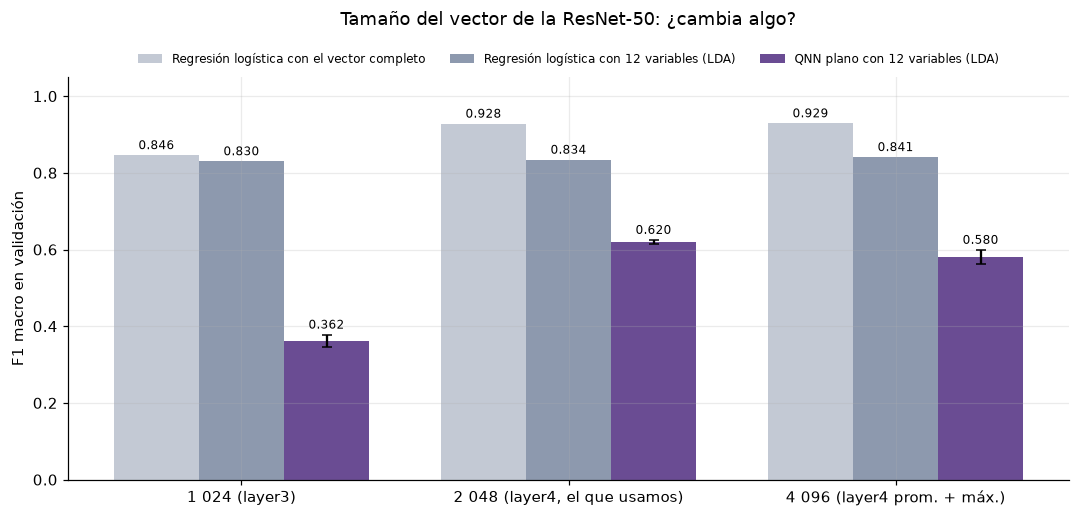

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.8))
cols = ["logística (vector completo)", "logística (LDA 12)", "QNN (LDA 12) media"]
etiquetas = ["Regresión logística con el vector completo", "Regresión logística con 12 variables (LDA)", "QNN plano con 12 variables (LDA)"]
colores = ["#c3c9d4", C_CLAS, C_QNN]
x = np.arange(len(tabA)); w = 0.26
for i, (c, et, col) in enumerate(zip(cols, etiquetas, colores)):
    err = tabA["QNN (LDA 12) desv."] if c.startswith("QNN") else None
    b = ax.bar(x + (i - 1) * w, tabA[c], w, yerr=err, capsize=3, color=col, label=et)
    ax.bar_label(b, fmt="%.3f", fontsize=8, padding=2)
ax.set_xticks(x, tabA.index); ax.set_ylim(0, 1.05); ax.set_ylabel("F1 macro en validación")
ax.set_title("Tamaño del vector de la ResNet-50: ¿cambia algo?", pad=34)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

## 4. Qué nos dicen los resultados

**La comprobación sale bien.** El vector de 2 048 que extrajimos aquí es idéntico al del cuaderno principal (diferencia
máxima 0), y el QNN con la semilla 0 da 0.620 de media en validación, con 0.628 en la
semilla 0 contra 0.627 en el cuaderno principal. Los números de este anexo son comparables con los de allá.

**Con 1 024 (`layer3`) todo empeora, y el circuito mucho más.** La regresión logística con el vector completo baja de
0.928 a 0.846: las características de
una etapa antes son menos específicas y distinguen peor las razas. Lo llamativo es el QNN, que cae de
0.620 a 0.362, aunque una regresión logística con esas
mismas 12 variables todavía llega a 0.830. Es decir, las 12 variables de `layer3`
siguen separando bien las razas para un modelo lineal, pero el circuito no logra aprovecharlas. No investigamos la
causa; una hipótesis es que su distribución queda peor repartida en el intervalo $[0,\pi]$ que usamos como ángulos,
como pasó con el LDA con *shrinkage* en el cuaderno principal.

**Con 4 096 (`layer4` promedio + máximo) no se gana nada.** Con el vector completo, la regresión logística queda
prácticamente igual (0.929 contra 0.928);
con 12 variables sube un poco (0.841 contra 0.834), una
diferencia del orden del ruido con 552 fotos de validación. Y el QNN **empeora**:
0.580 ± 0.019 contra
0.620 ± 0.005. Duplicar el vector duplica la memoria y el
costo de la reducción sin aportar información nueva sobre la raza: el *pooling* máximo resume los mismos mapas de
`layer4` que el promedio.

**Conclusión.** El 2 048 no fue un número elegido a mano sino el tamaño natural de la representación final de la
ResNet-50, y de las tres opciones que probamos con la misma red es la que mejor le funciona al circuito:
0.620 de F1 en validación contra 0.362 con 1 024 y
0.580 con 4 096, con la menor variación entre semillas. Lo que cuenta no es cuántos números
trae el vector, sino qué tan bien describe la raza.

**Limitaciones.** Una sola partición y 552 fotos de validación. El vector de 4 096 es una construcción nuestra con la
misma red; una red que da 4 096 de forma natural, como VGG-16, cambiaría también el entrenamiento previo y la calidad
de las características, así que no sería una comparación solo de tamaño. No probamos otras redes.